In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import plotly.express as px

In [2]:
adae = pd.read_csv("adae_pds2019.csv")
adlb = pd.read_csv("adlb_pds2019.csv")
adls = pd.read_csv("adls_pds2019.csv")
adpm = pd.read_csv("adpm_pds2019.csv")
adrsp = pd.read_csv("adrsp_pds2019.csv")
adsl = pd.read_csv("adsl_pds2019.csv")

In [3]:
adae['AESOC'].unique()

array(['Skin and subcutaneous tissue disorders',
       'Infections and infestations',
       'Injury, poisoning and procedural complications',
       'General disorders and administration site conditions',
       'Vascular disorders',
       'Neoplasms benign, malignant and unspecified (incl cysts and polyps)',
       'Hepatobiliary disorders',
       'Reproductive system and breast disorders',
       'Gastrointestinal disorders',
       'Respiratory, thoracic and mediastinal disorders',
       'Blood and lymphatic system disorders'], dtype=object)

In [4]:
adae.head()

,SUBJID,AEPT,AESOC,AESTDYI,AEENDYI,AESEVCD,AECONT
0,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,12.0,29.0,1.0,N
1,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,41.0,57.0,1.0,N
2,7,Rash,Skin and subcutaneous tissue disorders,9.0,127.0,1.0,N
3,7,Rash,Skin and subcutaneous tissue disorders,128.0,141.0,2.0,N
4,7,Rash,Skin and subcutaneous tissue disorders,142.0,160.0,1.0,N


In [5]:
def categorize_month(days):
    if 0 <= days <= 30:
        return 'month1'
    elif 31 <= days <= 60:
        return 'month2'
    else:
        return 'month>2'

# Apply the function to the 'AEENDYI' column and create a new 'Month' column
adae['Month'] = adae['AESTDYI'].apply(categorize_month)

In [6]:
adae.head()

,SUBJID,AEPT,AESOC,AESTDYI,AEENDYI,AESEVCD,AECONT,Month
0,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,12.0,29.0,1.0,N,month1
1,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,41.0,57.0,1.0,N,month2
2,7,Rash,Skin and subcutaneous tissue disorders,9.0,127.0,1.0,N,month1
3,7,Rash,Skin and subcutaneous tissue disorders,128.0,141.0,2.0,N,month>2
4,7,Rash,Skin and subcutaneous tissue disorders,142.0,160.0,1.0,N,month>2


In [7]:
print(len(adae))

3211


In [8]:
adae = adae.drop(columns=['AEENDYI'])

In [9]:
print(len(adae))

3211


In [10]:
rows_with_nan = adae[adae.isna().any(axis=1) | (adae == '').any(axis=1)]

print("\nRows with at least one NaN or blank value:")
print(rows_with_nan)


Rows with at least one NaN or blank value:
      SUBJID              AEPT                                   AESOC  \
591      259  Skin exfoliation  Skin and subcutaneous tissue disorders   
2960    1100              Rash  Skin and subcutaneous tissue disorders   

      AESTDYI  AESEVCD AECONT    Month  
591     184.0      NaN      N  month>2  
2960     85.0      NaN      N  month>2  


In [11]:
adae = adae.dropna()

# Drop rows with any blank values
adae = adae[~(adae == '').any(axis=1)]

In [12]:
print(len(adae))

3209


In [13]:
adae

,SUBJID,AEPT,AESOC,AESTDYI,AESEVCD,AECONT,Month
0,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,12.0,1.0,N,month1
1,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,41.0,1.0,N,month2
2,7,Rash,Skin and subcutaneous tissue disorders,9.0,1.0,N,month1
3,7,Rash,Skin and subcutaneous tissue disorders,128.0,2.0,N,month>2
4,7,Rash,Skin and subcutaneous tissue disorders,142.0,1.0,N,month>2
...,...,...,...,...,...,...,...
3206,1182,Rash,Skin and subcutaneous tissue disorders,161.0,2.0,N,month>2
3207,1182,Rash,Skin and subcutaneous tissue disorders,185.0,1.0,Y,month>2
3208,1182,Rash,Skin and subcutaneous tissue disorders,196.0,1.0,Y,month>2
3209,1182,Rash,Skin and subcutaneous tissue disorders,196.0,1.0,Y,month>2


In [14]:
adae_Y = adae.drop(columns=['AECONT'])
adae_Y.head()
adae_Y.drop(columns=['AEPT'], inplace=True)

adae_Y['Total_AE'] = adae_Y.groupby(['SUBJID', 'Month'])['AESOC'].transform('nunique')

adae_Y = adae_Y.drop_duplicates(subset=['SUBJID', 'Month'])

unique_subjids = adae_Y['SUBJID'].unique()
month_categories = ['month1', 'month2', 'month>2']

# Create a DataFrame with all combinations of SUBJID and month categories
all_combinations = pd.MultiIndex.from_product([unique_subjids, month_categories], names=['SUBJID', 'Month']).to_frame(index=False)

# Merge with the original DataFrame
merged = all_combinations.merge(adae_Y, on=['SUBJID', 'Month'], how='left')

# Fill missing values
merged['AESOC'] = merged['AESOC'].fillna('')  # Or any default value you prefer
merged['AESTDYI'] = merged['AESTDYI'].fillna(0)
merged['AESEVCD'] = merged['AESEVCD'].fillna(0)
merged['Total_AE'] = merged['Total_AE'].fillna(0)

# Display the resulting DataFrame
print(merged)

adae1 = merged.drop(columns=['AESTDYI', 'AESEVCD'])

final_df = pd.merge(adae1, adsl, on='SUBJID', how='left')

# Display the resulting DataFrame
print(final_df)



      SUBJID    Month                                   AESOC  AESTDYI  \
0          3   month1  Skin and subcutaneous tissue disorders     12.0   
1          3   month2  Skin and subcutaneous tissue disorders     41.0   
2          3  month>2                                              0.0   
3          7   month1  Skin and subcutaneous tissue disorders      9.0   
4          7   month2                                              0.0   
...      ...      ...                                     ...      ...   
1819    1181   month2  Skin and subcutaneous tissue disorders     36.0   
1820    1181  month>2  Skin and subcutaneous tissue disorders     81.0   
1821    1182   month1                                              0.0   
1822    1182   month2                                              0.0   
1823    1182  month>2  Skin and subcutaneous tissue disorders     72.0   

      AESEVCD  Total_AE  
0         1.0       1.0  
1         1.0       1.0  
2         0.0       0.0  
3      

In [15]:
adae_Y = adae.drop(columns=['AECONT'])

In [16]:
adae_Y.head()

,SUBJID,AEPT,AESOC,AESTDYI,AESEVCD,Month
0,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,12.0,1.0,month1
1,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,41.0,1.0,month2
2,7,Rash,Skin and subcutaneous tissue disorders,9.0,1.0,month1
3,7,Rash,Skin and subcutaneous tissue disorders,128.0,2.0,month>2
4,7,Rash,Skin and subcutaneous tissue disorders,142.0,1.0,month>2


In [17]:
adae_Y.drop(columns=['AEPT'], inplace=True)

adae_Y['Total_AE'] = adae_Y.groupby(['SUBJID', 'Month'])['AESOC'].transform('nunique')

adae_Y = adae_Y.drop_duplicates(subset=['SUBJID', 'Month'])

In [18]:
adae_Y.head(20)

,SUBJID,AESOC,AESTDYI,AESEVCD,Month,Total_AE
0,3,Skin and subcutaneous tissue disorders,12.0,1.0,month1,1
1,3,Skin and subcutaneous tissue disorders,41.0,1.0,month2,1
2,7,Skin and subcutaneous tissue disorders,9.0,1.0,month1,1
3,7,Skin and subcutaneous tissue disorders,128.0,2.0,month>2,2
10,9,Skin and subcutaneous tissue disorders,3.0,2.0,month1,1
13,9,Skin and subcutaneous tissue disorders,32.0,2.0,month2,1
15,9,Skin and subcutaneous tissue disorders,78.0,1.0,month>2,1
24,13,Skin and subcutaneous tissue disorders,37.0,2.0,month2,1
27,15,Skin and subcutaneous tissue disorders,69.0,1.0,month>2,2
35,17,Skin and subcutaneous tissue disorders,175.0,2.0,month>2,1


In [19]:
unique_subjids = adae_Y['SUBJID'].unique()
month_categories = ['month1', 'month2', 'month>2']

# Create a DataFrame with all combinations of SUBJID and month categories
all_combinations = pd.MultiIndex.from_product([unique_subjids, month_categories], names=['SUBJID', 'Month']).to_frame(index=False)

# Merge with the original DataFrame
merged = all_combinations.merge(adae_Y, on=['SUBJID', 'Month'], how='left')

# Fill missing values
merged['AESOC'] = merged['AESOC'].fillna('')  # Or any default value you prefer
merged['AESTDYI'] = merged['AESTDYI'].fillna(0)
merged['AESEVCD'] = merged['AESEVCD'].fillna(0)
merged['Total_AE'] = merged['Total_AE'].fillna(0)

# Display the resulting DataFrame
print(merged)

      SUBJID    Month                                   AESOC  AESTDYI  \
0          3   month1  Skin and subcutaneous tissue disorders     12.0   
1          3   month2  Skin and subcutaneous tissue disorders     41.0   
2          3  month>2                                              0.0   
3          7   month1  Skin and subcutaneous tissue disorders      9.0   
4          7   month2                                              0.0   
...      ...      ...                                     ...      ...   
1819    1181   month2  Skin and subcutaneous tissue disorders     36.0   
1820    1181  month>2  Skin and subcutaneous tissue disorders     81.0   
1821    1182   month1                                              0.0   
1822    1182   month2                                              0.0   
1823    1182  month>2  Skin and subcutaneous tissue disorders     72.0   

      AESEVCD  Total_AE  
0         1.0       1.0  
1         1.0       1.0  
2         0.0       0.0  
3      

In [20]:
adae1 = merged.drop(columns=['AESTDYI', 'AESEVCD'])

In [21]:
adae1.head()

,SUBJID,Month,AESOC,Total_AE
0,3,month1,Skin and subcutaneous tissue disorders,1.0
1,3,month2,Skin and subcutaneous tissue disorders,1.0
2,3,month>2,,0.0
3,7,month1,Skin and subcutaneous tissue disorders,1.0
4,7,month2,,0.0


In [22]:
final_df = pd.merge(adae1, adsl, on='SUBJID', how='left')

# Display the resulting DataFrame
print(final_df)

      SUBJID    Month                                   AESOC  Total_AE  \
0          3   month1  Skin and subcutaneous tissue disorders       1.0   
1          3   month2  Skin and subcutaneous tissue disorders       1.0   
2          3  month>2                                               0.0   
3          7   month1  Skin and subcutaneous tissue disorders       1.0   
4          7   month2                                               0.0   
...      ...      ...                                     ...       ...   
1819    1181   month2  Skin and subcutaneous tissue disorders       1.0   
1820    1181  month>2  Skin and subcutaneous tissue disorders       1.0   
1821    1182   month1                                               0.0   
1822    1182   month2                                               0.0   
1823    1182  month>2  Skin and subcutaneous tissue disorders       1.0   

                       TRT                  ATRT PRSURG  DTHDY  DTH  PFSDYCR  \
0     Panitumumab +

In [23]:
numeric_cols = final_df.select_dtypes(include=['number']).columns
final_df[numeric_cols] = final_df[numeric_cols].fillna(0)


In [24]:

# Fill categorical columns with 'Unknown' or mode
categorical_cols = final_df.select_dtypes(include=['object']).columns
categorical_cols = categorical_cols.drop(['Month','AESOC','ATRT','TRT'])
for col in categorical_cols:
    if final_df[col].isnull().any() or (final_df[col] == '').any():
        if final_df[col].mode().any():
            final_df[col].fillna(final_df[col].mode()[0], inplace=True)
            final_df[col].replace('', final_df[col].mode()[0], inplace=True)
        else:
            final_df[col].fillna('Unknown', inplace=True)

In [25]:
final_df = pd.get_dummies(final_df, columns=categorical_cols, drop_first=False)

In [26]:
final_df.head()

,SUBJID,Month,AESOC,Total_AE,TRT,ATRT,DTHDY,DTH,PFSDYCR,PFSCR,...,B_ECOG_Fully active,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,HISSUBTY_Appendiceal,HISSUBTY_Mucinous,HISSUBTY_No sub-type,HISSUBTY_Other,HISSUBTY_Unknown,DIAGTYPE_Colon,DIAGTYPE_Rectal
0,3,month1,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,...,False,False,True,False,False,True,False,False,True,False
1,3,month2,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,...,False,False,True,False,False,True,False,False,True,False
2,3,month>2,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,...,False,False,True,False,False,True,False,False,True,False
3,7,month1,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,...,False,False,True,False,True,False,False,False,True,False
4,7,month2,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,...,False,False,True,False,True,False,False,False,True,False


In [27]:
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [28]:
def evaluate_and_plot(y_true, y_pred, model_name, target):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{model_name} RMSE for {target}: {rmse}")

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, y_pred, alpha=0.5)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2)
    plt.xlabel('True Values')
    plt.ylabel('Predicted Values')
    plt.title(f"{model_name} - {target} - True vs Predicted")
    plt.show()

def train_and_evaluate(model, X_train, y_train, X_val, y_val, X_test, y_test, model_name, target):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    evaluate_and_plot(y_test, y_pred, model_name, target)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_score = np.sqrt(mean_squared_error(y_train, train_pred))
    test_score =  np.sqrt(mean_squared_error(y_test, test_pred))

    print(f"{model_name} Training RMSE: {train_score}")
    print(f"{model_name} Test RMSE: {test_score}")

    # Create DataFrame with actual and predicted values
    comparison_df = pd.DataFrame({
        'Actual': y_test,
        'Predicted': y_pred
    })

    return model, comparison_df, train_score, test_score


In [29]:
def bin_predictions(predictions):
    bins = np.digitize(predictions, bins=[0.75, 1.25, 2.5, 3.5])
    return bins

In [30]:
def allpred(model_ae, X_ae):
    subjid = X_ae['SUBJID']
    ae_predictions = bin_predictions(model_ae.predict(X_ae))

    # DataFrame with SUBJID, ae_predictions, and sae_predictions
    result_df = pd.DataFrame({
        'SUBJID': subjid,
        'AE_Predictions': ae_predictions
    })

    return result_df


# Month1

In [31]:
m1_ae = final_df[final_df['Month'] == 'month1'].copy()
m1_ae.drop(columns=['Month',],inplace=True)
m1_ae.head()

,SUBJID,AESOC,Total_AE,TRT,ATRT,DTHDY,DTH,PFSDYCR,PFSCR,DIAGMONS,...,B_ECOG_Fully active,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,HISSUBTY_Appendiceal,HISSUBTY_Mucinous,HISSUBTY_No sub-type,HISSUBTY_Other,HISSUBTY_Unknown,DIAGTYPE_Colon,DIAGTYPE_Rectal
0,3,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,1.868852,...,False,False,True,False,False,True,False,False,True,False
3,7,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,2.786885,...,False,False,True,False,True,False,False,False,True,False
6,9,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,696.0,1.0,301.0,1.0,75.704918,...,True,False,False,False,False,True,False,False,True,False
9,13,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,197.0,1.0,73.0,1.0,2.032787,...,True,False,False,False,False,False,True,False,False,True
12,15,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,414.0,1.0,414.0,1.0,3.803279,...,False,False,True,False,False,True,False,False,False,True


In [32]:
m1_ae.drop(columns=['TRT','ATRT','AESOC'],inplace=True)

Text(0.5, 1.0, 'Distribution of total AE')

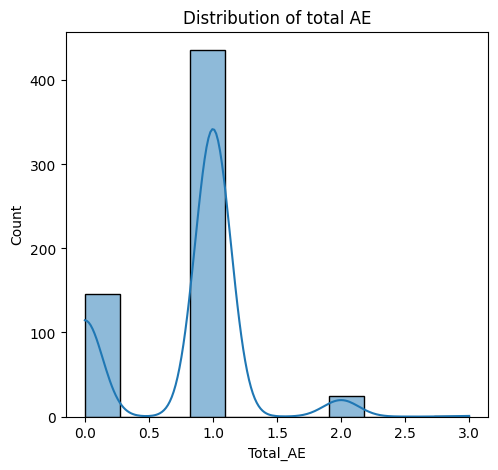

In [33]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(m1_ae['Total_AE'], kde=True)
plt.title('Distribution of total AE')

In [34]:
X = m1_ae.drop(columns=['Total_AE'])
y = m1_ae['Total_AE']

In [35]:
scaler = StandardScaler()
subjid = X['SUBJID']
features = X.drop(columns=['SUBJID'])
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

features_scaled = pd.DataFrame(features_scaled, columns=features.columns)

X_scaled = pd.concat([subjid.reset_index(drop=True), features_scaled], axis=1)

In [36]:
# For total_AE
rf_ae = RandomForestRegressor(n_estimators=150,max_depth= 5, random_state=42)
rf_ae.fit(X_scaled, y)
feature_importance_ae = pd.DataFrame({'feature': X.columns, 'importance': rf_ae.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)


In [37]:
print("Top features for total_AE:")
print(feature_importance_ae.head(30))

Top features for total_AE:
                                    feature  importance
5                                  DIAGMONS    0.182205
8                                  B_HEIGHT    0.137829
7                                  B_WEIGHT    0.129171
3                                   PFSDYCR    0.117773
1                                     DTHDY    0.116307
0                                    SUBJID    0.114290
6                                       AGE    0.088615
9                                  B_METANM    0.030063
28                         HISSUBTY_Unknown    0.008890
4                                     PFSCR    0.007954
26                     HISSUBTY_No sub-type    0.007006
17           RACE_Black or African American    0.006238
22  B_ECOG_In bed less than 50% of the time    0.006155
30                          DIAGTYPE_Rectal    0.004321
23           B_ECOG_Symptoms but ambulatory    0.003990
16                               RACE_Asian    0.003815
2                    

In [38]:
top_features_ae = feature_importance_ae['feature'][:30].tolist()

In [39]:
X_ae = X_scaled[top_features_ae]
X_train_ae, X_temp, y_ae_train, y_ae_temp = train_test_split(X_ae, y, test_size=0.4, random_state=42)
X_val_ae, X_test_ae, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.5, random_state=42)

In [40]:
# from sklearn.model_selection import RandomizedSearchCV
# from scipy.stats import uniform, randint

# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train_ae, y_ae_train)

# best_params = random_search.best_params_
# best_model = random_search.best_estimator_

In [41]:
best_params

NameError: name 'best_params' is not defined

XGBoost RMSE for AE: 0.5189201428473215


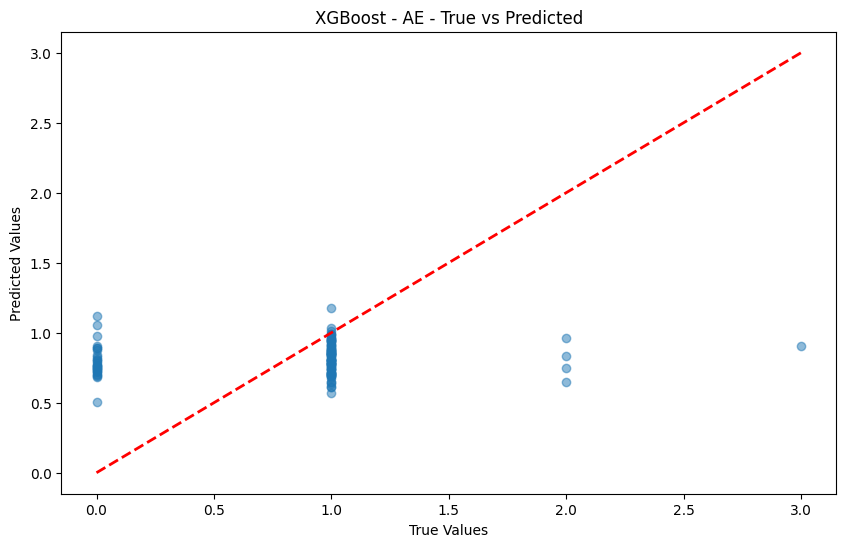

XGBoost Training RMSE: 0.399219645247073
XGBoost Test RMSE: 0.5189201428473215


In [42]:
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=143,
        learning_rate=0.024,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.9421,
        colsample_bytree=0.6464,
        gamma=0
    ),
    X_train_ae, y_ae_train, X_val_ae, y_ae_val, X_test_ae, y_ae_test, "XGBoost", "AE"
)

In [43]:
#xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
# compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': bin_predictions(xgb_ae_comparison['Predicted'].values)})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)

sum of absolute diff between predicted and actual AE:  49.0
max value abs diff in AE:  2.0
average deviation in predicted and actual AE:  0.4016393442622951


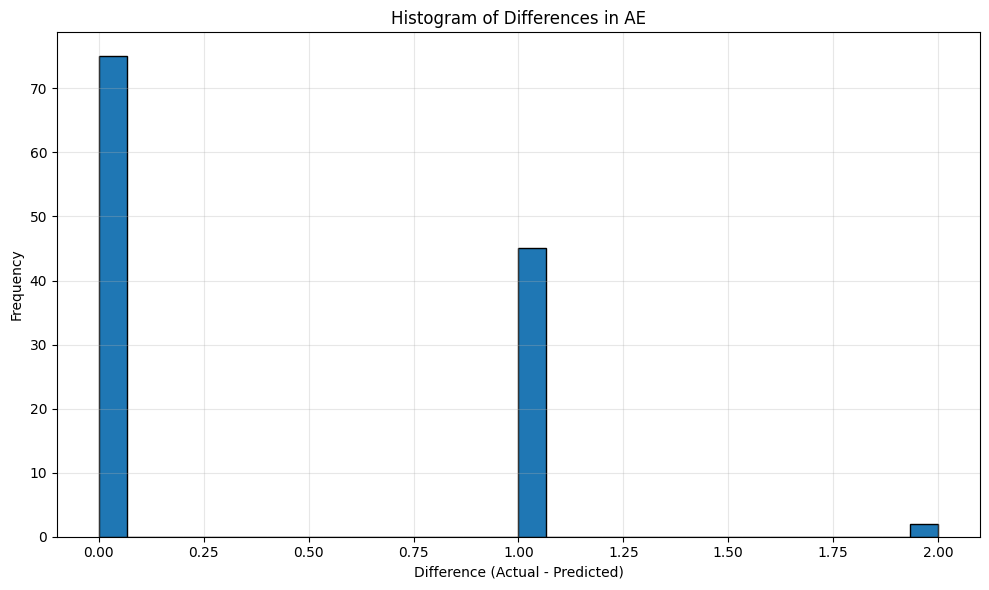

In [44]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

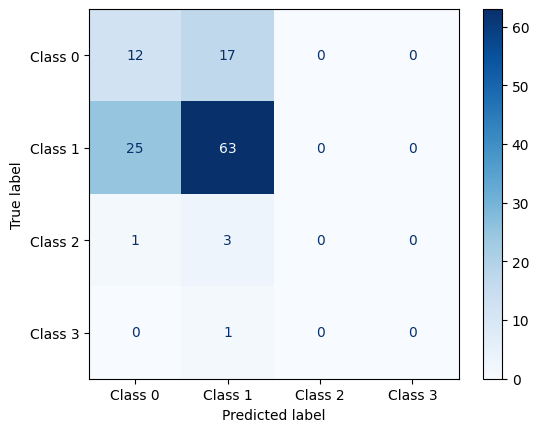

In [47]:
# Assuming y_pred are your predictions and y_true are the actual values
y_pred_class = compdf_xgb['predicted_AE'].astype(int)  # Round predictions and convert to integer classes
y_true_class = compdf_xgb['actual_AE'].astype(int)  # Round true values and convert to integer classes

# Create the confusion matrix
cm = confusion_matrix(y_true_class, y_pred_class)

# Display the confusion matrix
classes = ['Class 0', 'Class 1', 'Class 2','Class 3']  # Labels for each class
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap='Blues')

# Month2

In [48]:
m2_ae = final_df[final_df['Month'] == 'month2'].copy()
m2_ae.drop(columns=['Month',],inplace=True)
m2_ae.head()

,SUBJID,AESOC,Total_AE,TRT,ATRT,DTHDY,DTH,PFSDYCR,PFSCR,DIAGMONS,...,B_ECOG_Fully active,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,HISSUBTY_Appendiceal,HISSUBTY_Mucinous,HISSUBTY_No sub-type,HISSUBTY_Other,HISSUBTY_Unknown,DIAGTYPE_Colon,DIAGTYPE_Rectal
1,3,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,1.868852,...,False,False,True,False,False,True,False,False,True,False
4,7,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,2.786885,...,False,False,True,False,True,False,False,False,True,False
7,9,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,696.0,1.0,301.0,1.0,75.704918,...,True,False,False,False,False,True,False,False,True,False
10,13,Skin and subcutaneous tissue disorders,1.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,197.0,1.0,73.0,1.0,2.032787,...,True,False,False,False,False,False,True,False,False,True
13,15,,0.0,Panitumumab + FOLFOX,Panitumumab + FOLFOX,414.0,1.0,414.0,1.0,3.803279,...,False,False,True,False,False,True,False,False,False,True


In [49]:
m2_ae.drop(columns=['TRT','ATRT','AESOC'],inplace=True)

In [50]:
y_all = allpred(xgb_ae,X_ae)

In [51]:
X1 = y_all
X1.rename(columns={'AE_Predictions': 'month1_AE', 'SAE_Predictions': 'month1_SAE'}, inplace=True)
X1

,SUBJID,month1_AE
0,3,0
1,7,0
2,9,0
3,13,0
4,15,0
...,...,...
603,1169,0
604,1171,0
605,1172,1
606,1181,1


In [52]:
m2_ae = pd.merge(m2_ae,X1,on=['SUBJID'],how='left')
print(m2_ae)

     SUBJID  Total_AE   DTHDY  DTH  PFSDYCR  PFSCR   DIAGMONS   AGE  B_WEIGHT  \
0         3       1.0   301.0  1.0     54.0    1.0   1.868852  65.0      67.0   
1         7       0.0   339.0  1.0    339.0    1.0   2.786885  52.0      53.0   
2         9       1.0   696.0  1.0    301.0    1.0  75.704918  42.0      69.0   
3        13       1.0   197.0  1.0     73.0    1.0   2.032787  54.0      62.0   
4        15       0.0   414.0  1.0    414.0    1.0   3.803279  67.0      48.8   
..      ...       ...     ...  ...      ...    ...        ...   ...       ...   
603    1169       1.0  1035.0  0.0    395.0    1.0   0.459016  61.0      66.5   
604    1171       0.0   486.0  1.0    169.0    1.0   2.065574  72.0      53.0   
605    1172       1.0   947.0  1.0    269.0    1.0   6.655738  72.0      67.3   
606    1181       1.0   672.0  1.0    184.0    1.0  65.081967  36.0     111.0   
607    1182       0.0   684.0  1.0    287.0    1.0   0.950820  75.0      69.5   

     B_HEIGHT  ...  B_ECOG_

Text(0.5, 1.0, 'Distribution of total AE')

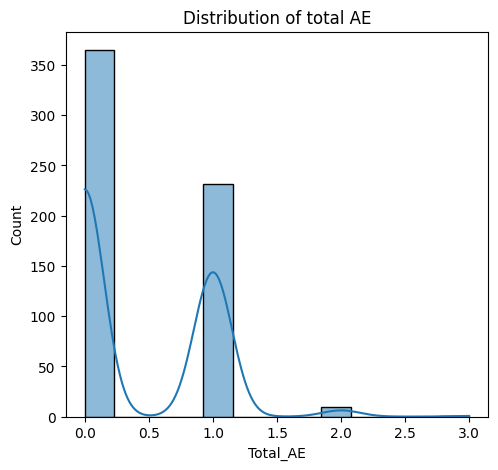

In [53]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(m2_ae['Total_AE'], kde=True)
plt.title('Distribution of total AE')

In [54]:
X = m2_ae.drop(columns=['Total_AE'])
y = m2_ae['Total_AE']

In [55]:
scaler = StandardScaler()
subjid = X['SUBJID']
features = X.drop(columns=['SUBJID'])
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

features_scaled = pd.DataFrame(features_scaled, columns=features.columns)

X_scaled = pd.concat([subjid.reset_index(drop=True), features_scaled], axis=1)

In [56]:
# For total_AE
rf_ae = RandomForestRegressor(n_estimators=150,max_depth= 5, random_state=42)
rf_ae.fit(X_scaled, y)
feature_importance_ae = pd.DataFrame({'feature': X.columns, 'importance': rf_ae.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)


In [57]:
print("Top features for total_AE:")
print(feature_importance_ae.head(30))

Top features for total_AE:
                                    feature  importance
31                                month1_AE    0.180703
1                                     DTHDY    0.128708
5                                  DIAGMONS    0.120087
3                                   PFSDYCR    0.114888
0                                    SUBJID    0.091989
7                                  B_WEIGHT    0.087049
6                                       AGE    0.079431
8                                  B_HEIGHT    0.073823
9                                  B_METANM    0.029935
18                  RACE_Hispanic or Latino    0.012114
26                     HISSUBTY_No sub-type    0.008007
28                         HISSUBTY_Unknown    0.007607
23           B_ECOG_Symptoms but ambulatory    0.005799
4                                     PFSCR    0.005291
15                                 SEX_Male    0.005180
29                           DIAGTYPE_Colon    0.005136
21                   

In [58]:
top_features_ae = feature_importance_ae['feature'][:30].tolist()

In [59]:
top_features_ae = ['month1_AE','DTHDY','DIAGMONS','PFSDYCR','SUBJID','AGE','B_WEIGHT','B_HEIGHT','SEX_Male','B_METANM']

In [60]:
X_ae = X_scaled[top_features_ae]
X_train_ae, X_temp, y_ae_train, y_ae_temp = train_test_split(X_ae, y, test_size=0.4, random_state=42)
X_val_ae, X_test_ae, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.5, random_state=42)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_distributions = {
    'n_estimators': randint(50, 500),
    'learning_rate': uniform(0.01, 0.3),
    'max_depth': randint(3, 10),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4)
}
random_state=42
xgb = XGBRegressor(random_state=random_state)
random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
random_search.fit(X_train_ae, y_ae_train)

best_params = random_search.best_params_
best_model = random_search.best_estimator_

In [ ]:
best_params

XGBoost RMSE for AE: 0.5142361731240764


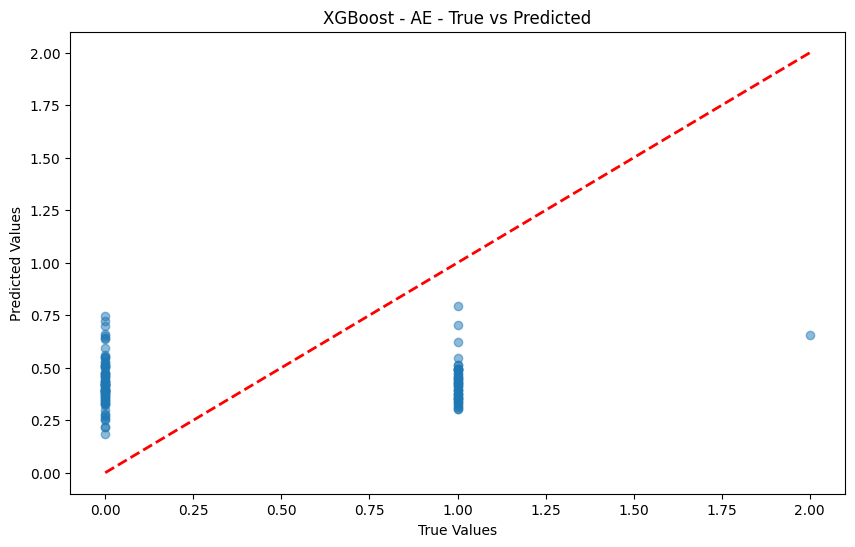

XGBoost Training RMSE: 0.4628014011967146
XGBoost Test RMSE: 0.5142361731240764


In [61]:
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=98,
        learning_rate=0.021,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.8099,
        colsample_bytree=0.844,
        gamma=0
    ),
    X_train_ae, y_ae_train, X_val_ae, y_ae_val, X_test_ae, y_ae_test, "XGBoost", "AE"
)

In [62]:
def bin_predictions1(predictions):
    bins = np.digitize(predictions, bins=[0.6, 1.25, 2.5])
    return bins

In [63]:
#xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
# compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': bin_predictions1(xgb_ae_comparison['Predicted'].values)})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)

sum of absolute diff between predicted and actual AE:  52.0
max value abs diff in AE:  1.0
average deviation in predicted and actual AE:  0.4262295081967213


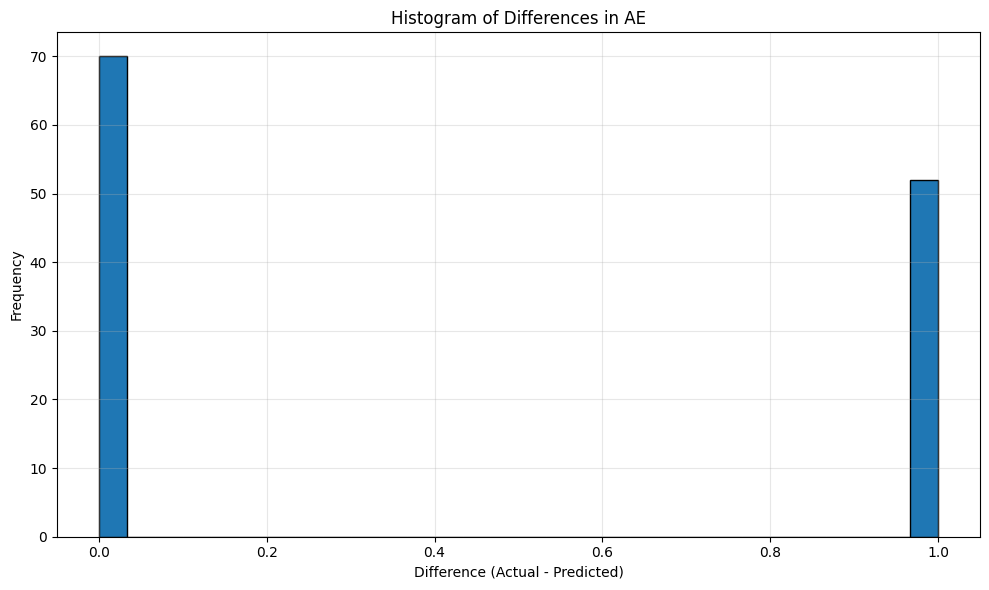

In [64]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

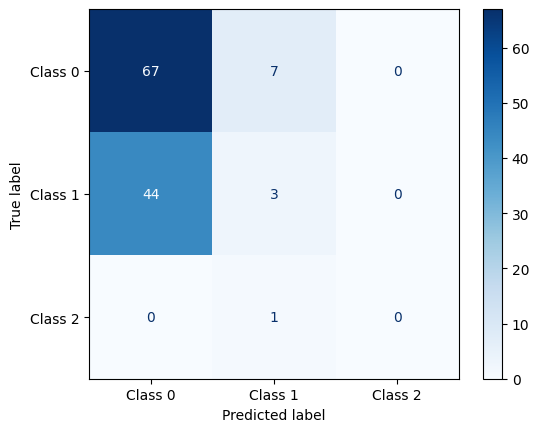

In [65]:
# Assuming y_pred are your predictions and y_true are the actual values
y_pred_class = compdf_xgb['predicted_AE'].astype(int)  # Round predictions and convert to integer classes
y_true_class = compdf_xgb['actual_AE'].astype(int)  # Round true values and convert to integer classes

# Create the confusion matrix
cm = confusion_matrix(y_true_class, y_pred_class)

# Display the confusion matrix
classes = ['Class 0', 'Class 1', 'Class 2']  # Labels for each class
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap='Blues')

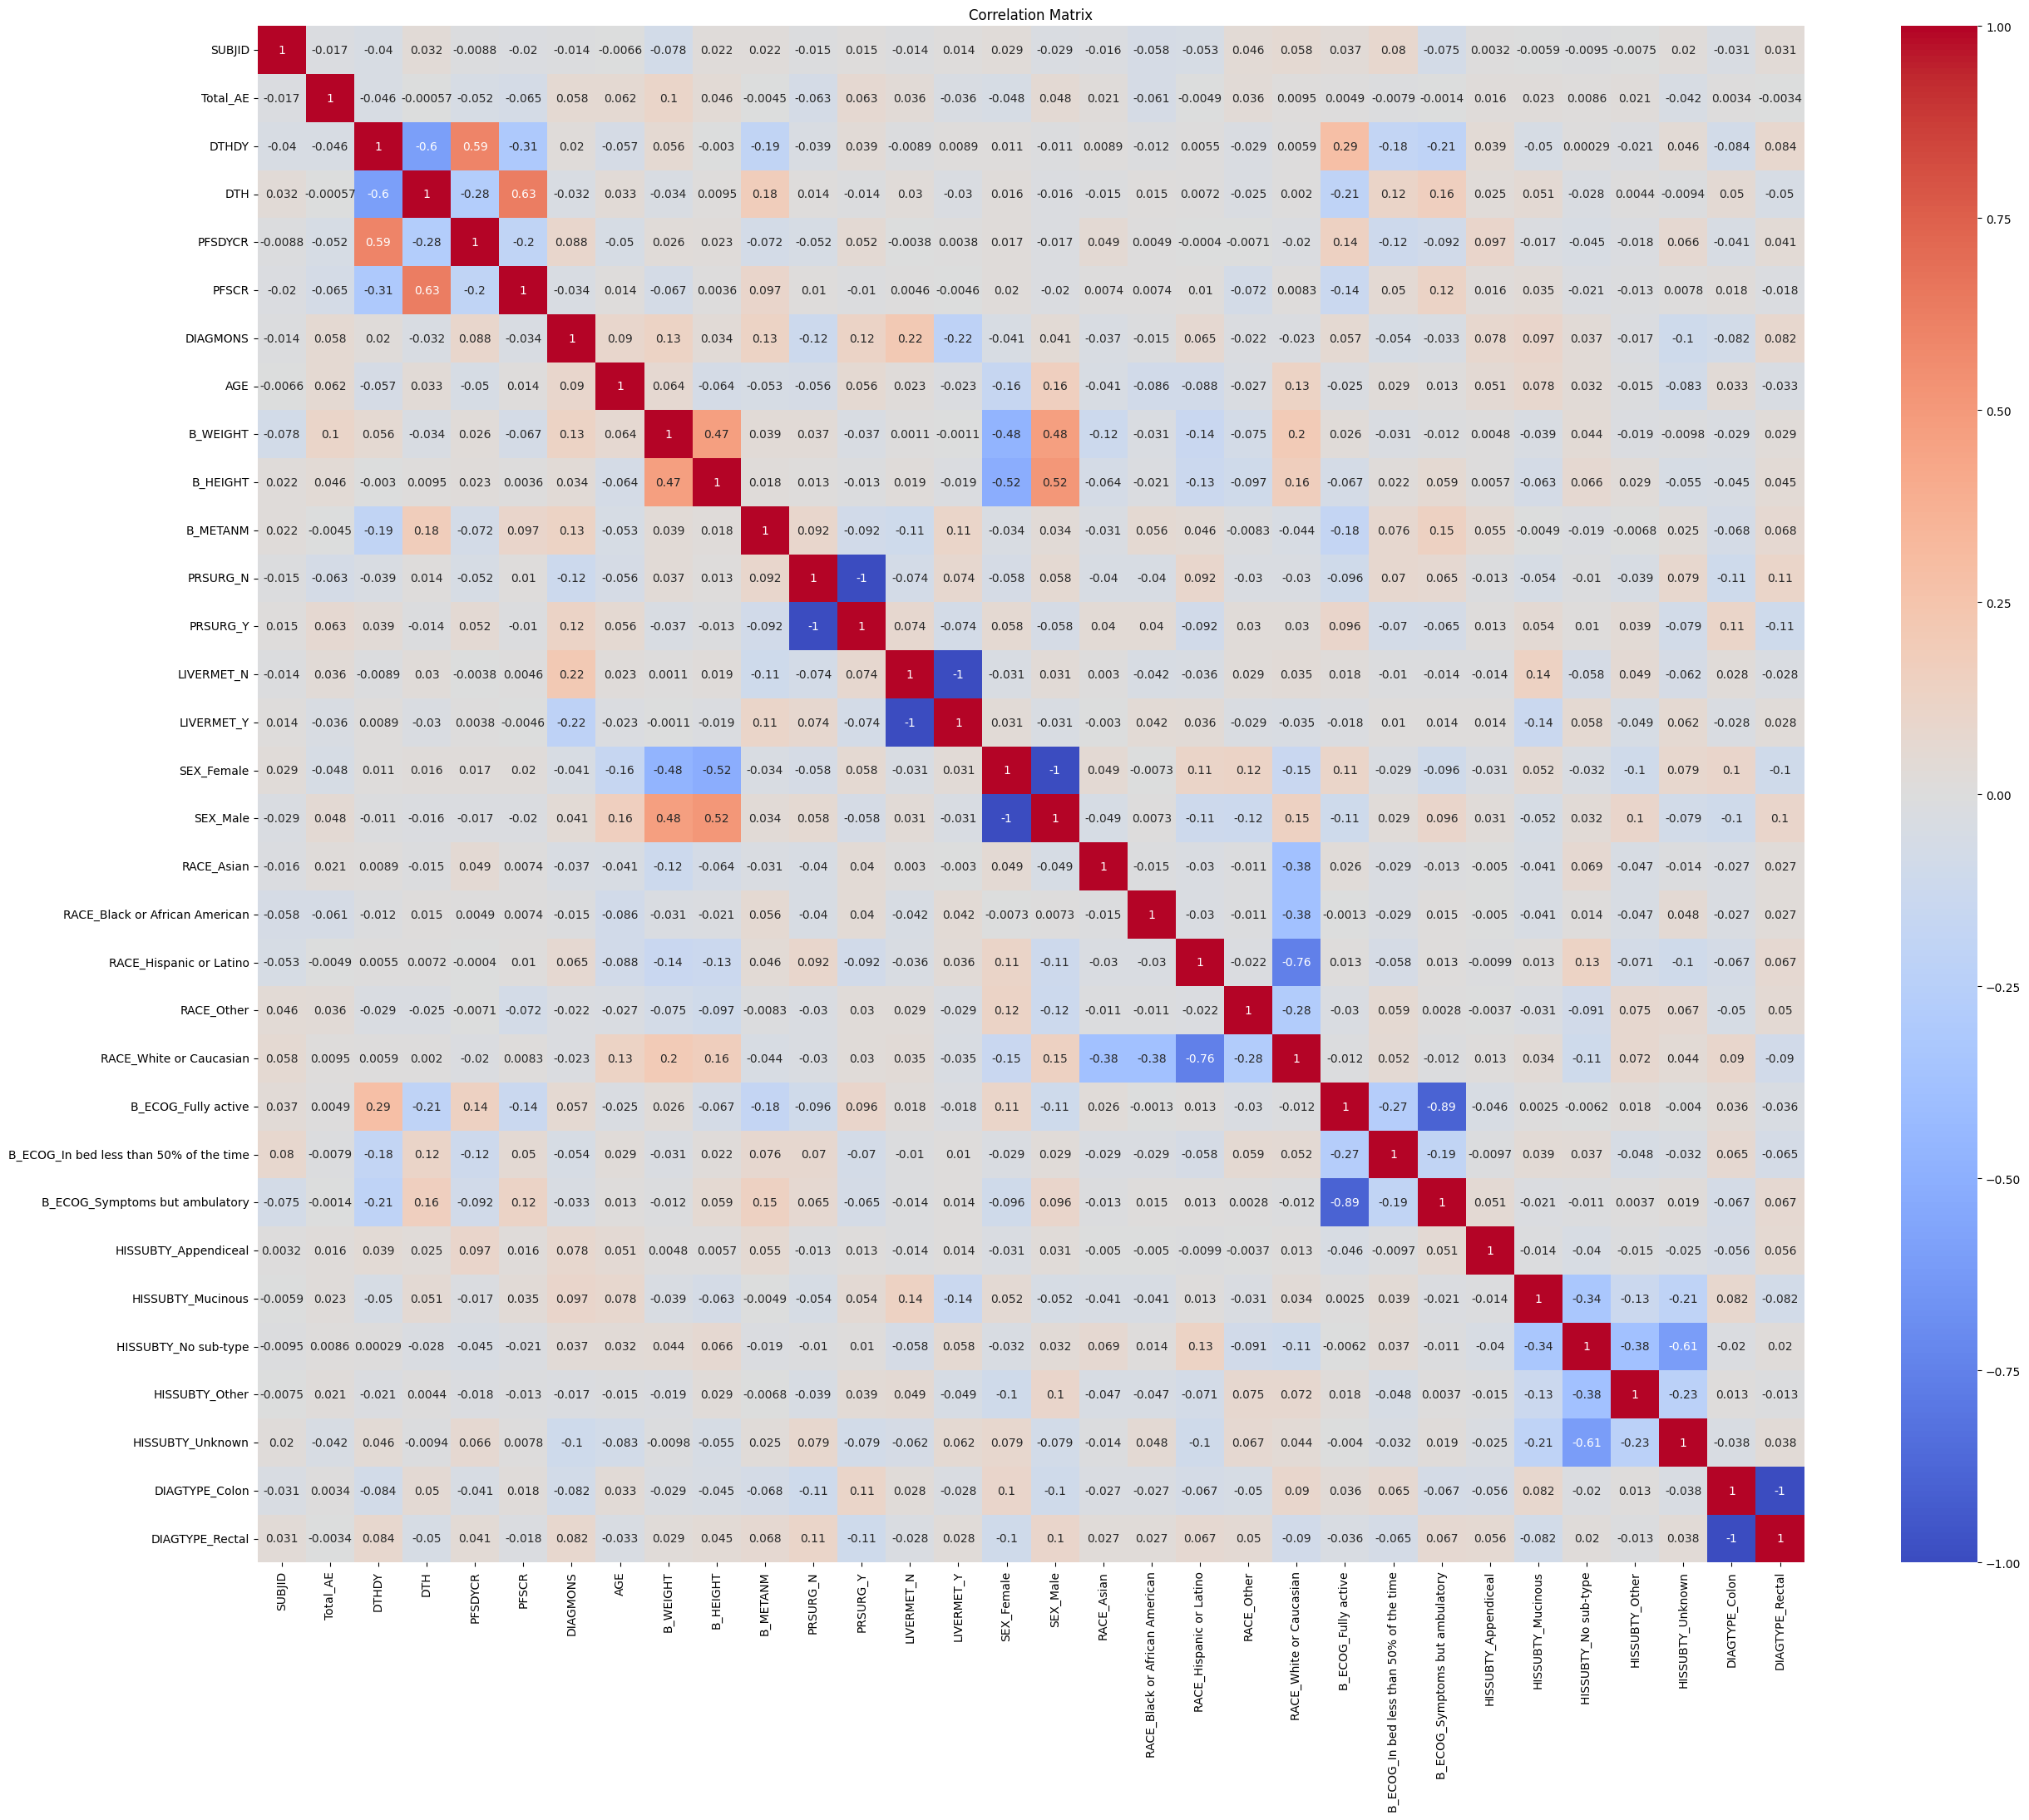

In [66]:
corr_matrix = m1_ae.corr()

# Create a heatmap of the correlation matrix
plt.figure(figsize=(30, 24))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix')
plt.show()

# Total without considering months



In [67]:
all_df = final_df.groupby('SUBJID').agg({
    'Total_AE': 'sum',
})

In [68]:
other_columns = final_df.drop(['Month', 'Total_AE'], axis=1).drop_duplicates(subset=['SUBJID'])

In [69]:
all_df = other_columns.merge(all_df, on='SUBJID', how='left')

In [70]:
all_df.head()

,SUBJID,AESOC,TRT,ATRT,DTHDY,DTH,PFSDYCR,PFSCR,DIAGMONS,AGE,...,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,HISSUBTY_Appendiceal,HISSUBTY_Mucinous,HISSUBTY_No sub-type,HISSUBTY_Other,HISSUBTY_Unknown,DIAGTYPE_Colon,DIAGTYPE_Rectal,Total_AE
0,3,Skin and subcutaneous tissue disorders,Panitumumab + FOLFOX,Panitumumab + FOLFOX,301.0,1.0,54.0,1.0,1.868852,65.0,...,False,True,False,False,True,False,False,True,False,2.0
1,7,Skin and subcutaneous tissue disorders,Panitumumab + FOLFOX,Panitumumab + FOLFOX,339.0,1.0,339.0,1.0,2.786885,52.0,...,False,True,False,True,False,False,False,True,False,3.0
2,9,Skin and subcutaneous tissue disorders,Panitumumab + FOLFOX,Panitumumab + FOLFOX,696.0,1.0,301.0,1.0,75.704918,42.0,...,False,False,False,False,True,False,False,True,False,3.0
3,13,,Panitumumab + FOLFOX,Panitumumab + FOLFOX,197.0,1.0,73.0,1.0,2.032787,54.0,...,False,False,False,False,False,True,False,False,True,1.0
4,15,,Panitumumab + FOLFOX,Panitumumab + FOLFOX,414.0,1.0,414.0,1.0,3.803279,67.0,...,False,True,False,False,True,False,False,False,True,2.0


In [71]:
all_df.drop(columns=['TRT','ATRT','AESOC'],inplace=True)

Text(0.5, 1.0, 'Distribution of total AE')

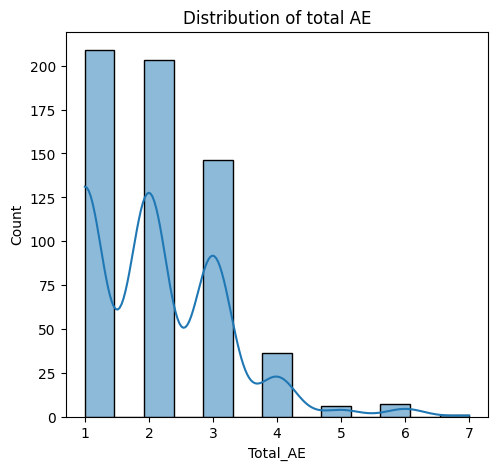

In [72]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(all_df['Total_AE'], kde=True)
plt.title('Distribution of total AE')

In [73]:
X = all_df.drop(columns=['Total_AE'])
y = all_df['Total_AE']

In [74]:
scaler = StandardScaler()
subjid = X['SUBJID']
features = X.drop(columns=['SUBJID'])
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

In [75]:
features_scaled = pd.DataFrame(features_scaled, columns=features.columns)

X_scaled = pd.concat([subjid.reset_index(drop=True), features_scaled], axis=1)

In [76]:
# For total_AE
rf_ae = RandomForestRegressor(n_estimators=150,max_depth= 5, random_state=42)
rf_ae.fit(X_scaled, y)
feature_importance_ae = pd.DataFrame({'feature': X.columns, 'importance': rf_ae.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)

print("Top features for total_AE:")
print(feature_importance_ae.head(30))

Top features for total_AE:
                                    feature  importance
1                                     DTHDY    0.196362
0                                    SUBJID    0.137833
7                                  B_WEIGHT    0.135556
8                                  B_HEIGHT    0.128688
5                                  DIAGMONS    0.123016
3                                   PFSDYCR    0.081570
6                                       AGE    0.066188
9                                  B_METANM    0.033614
18                  RACE_Hispanic or Latino    0.010415
16                               RACE_Asian    0.009228
20                  RACE_White or Caucasian    0.008179
28                         HISSUBTY_Unknown    0.006539
27                           HISSUBTY_Other    0.006490
2                                       DTH    0.006391
26                     HISSUBTY_No sub-type    0.006092
22  B_ECOG_In bed less than 50% of the time    0.005812
14                   

In [77]:
top_features_ae = feature_importance_ae['feature'][:30].tolist()

In [78]:
X_ae = X_scaled[top_features_ae]
X_train_ae, X_temp, y_ae_train, y_ae_temp = train_test_split(X_ae, y, test_size=0.4, random_state=42)
X_val_ae, X_test_ae, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.5, random_state=42)

In [79]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_distributions = {
    'n_estimators': randint(50, 500),
    'learning_rate': uniform(0.01, 0.3),
    'max_depth': randint(3, 10),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4)
}
random_state=42
xgb = XGBRegressor(random_state=random_state)
random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
random_search.fit(X_train_ae, y_ae_train)

best_params = random_search.best_params_
best_model = random_search.best_estimator_

KeyboardInterrupt: 

In [ ]:
best_params

XGBoost RMSE for AE: 1.0145958807745912


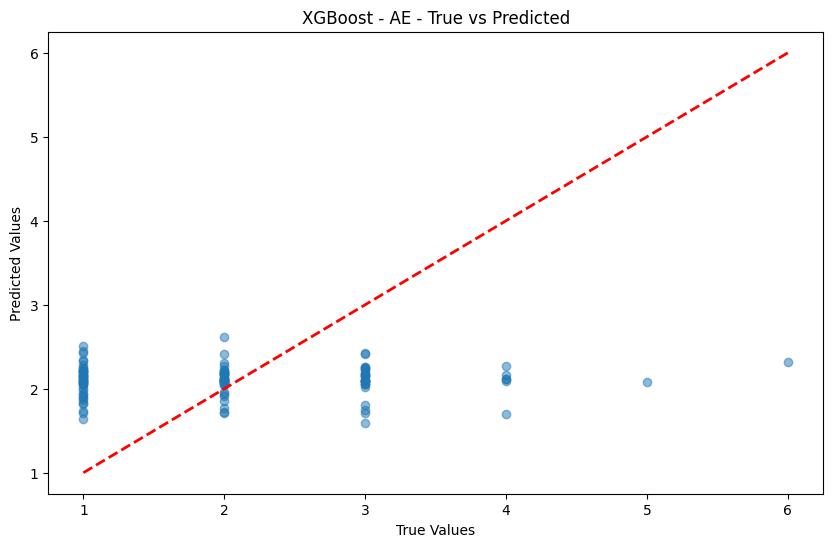

XGBoost Training RMSE: 0.9605978974755683
XGBoost Test RMSE: 1.0145958807745912


In [80]:
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=51,
        learning_rate=0.021,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.8010,
        colsample_bytree=0.713,
        gamma=0
    ),
    X_train_ae, y_ae_train, X_val_ae, y_ae_val, X_test_ae, y_ae_test, "XGBoost", "AE"
)

In [81]:
#xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
# compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': bin_predictions1(xgb_ae_comparison['Predicted'].values)})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)

sum of absolute diff between predicted and actual AE:  94.0
max value abs diff in AE:  4.0
average deviation in predicted and actual AE:  0.7704918032786885


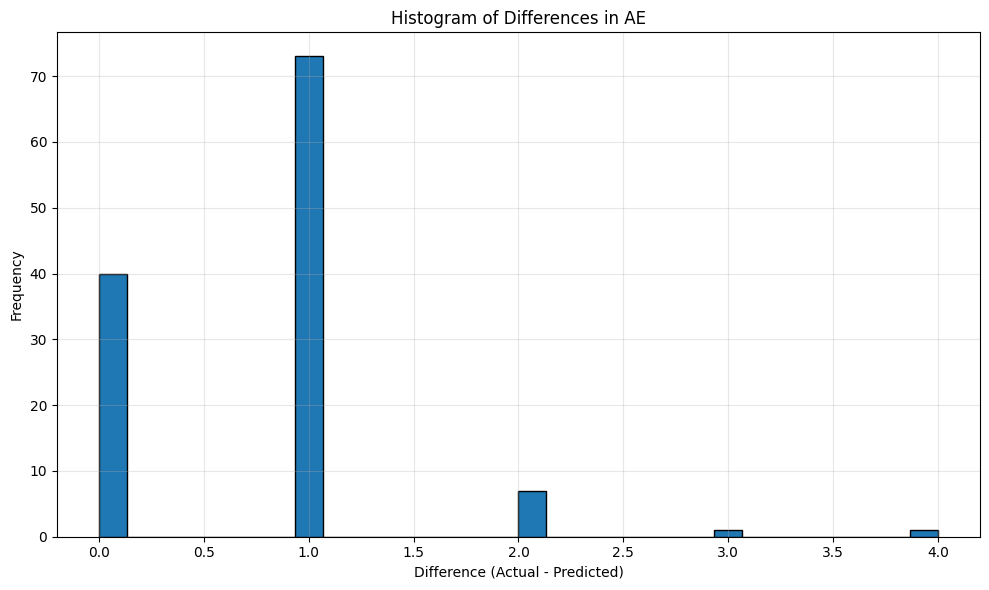

In [82]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()